# Simple Linear Regression | Radio Advertising & Sales
Explore whether radio advertising spending is associated with sales, using OLS (ordinary least squares) regression

## Workflow
- Import libraries
- Inspect and explore our dataset
- Explore relationship in the data
- Split observations into training and test sets
- Fit an OLS regression model to our data
- Review coefficients and statistical significance
- Evaluate regression assumptions
- Generate predications and evaluate on unseen data
- Summarize our findings

### 1. Import Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns # via library built off of matplotlib
import statsmodels.api as sm

from statsmodels.formula.api import ols
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 2. Inspect & Explore Data

In [19]:
df = pd.read_csv('marketing_sales_data.csv')

df.head()


,TV,Radio,Social Media,Influencer,Sales
0,Low,3.518070,2.293790,Micro,55.261284
1,Low,7.756876,2.572287,Mega,67.574904
2,High,20.348988,1.227180,Micro,272.250108
3,Medium,20.108487,2.728374,Mega,195.102176
4,High,31.653200,7.776978,Nano,273.960377


In [20]:
rows, cols = df.shape
print(f'Rows: {rows}')
print(f'Cols: {cols}')

Rows: 572
Cols: 5


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 572 entries, 0 to 571
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TV            572 non-null    object 
 1   Radio         572 non-null    float64
 2   Social Media  572 non-null    float64
 3   Influencer    572 non-null    object 
 4   Sales         572 non-null    float64
dtypes: float64(3), object(2)
memory usage: 22.5+ KB


In [22]:
print('Missing values by column:')
print(df.isnull().sum())

Missing values by column:
TV              0
Radio           0
Social Media    0
Influencer      0
Sales           0
dtype: int64


In [24]:
print(f'Duplicate Records:{df.duplicated().sum()}')

Duplicate Records:0


### 3. Explore relationships in the Data
Assumptions of linear regression
- linear relationship: the variables included express a linear (line) relationship with each other
- no-multi collinearity (multiple linear regressions) - the independent variables are not related to each other
- homoskedacity - errors should be consistent across the board

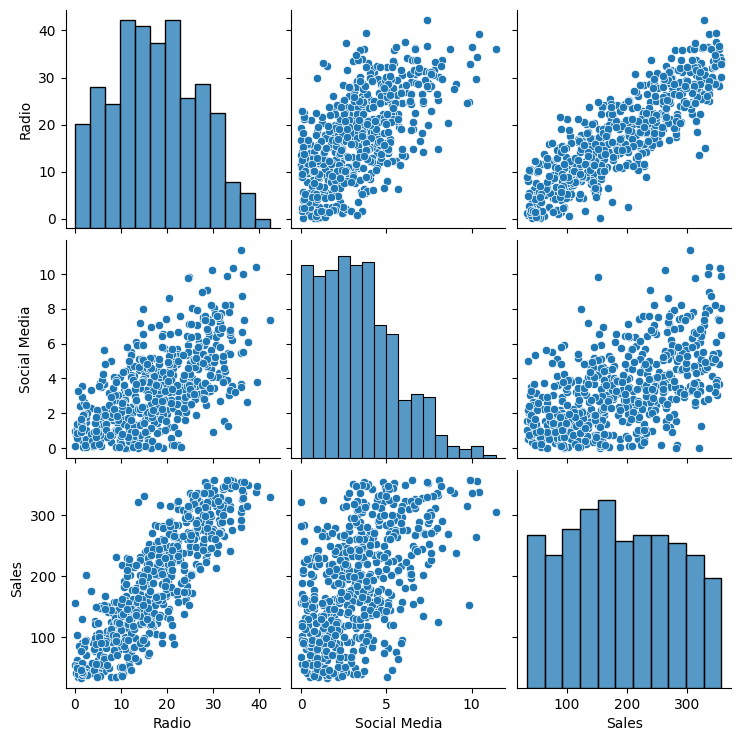

In [25]:
#Plot that pairs all quantitative variables in the dataset to quickly scan for relationships
sns.pairplot(df)
plt.show()

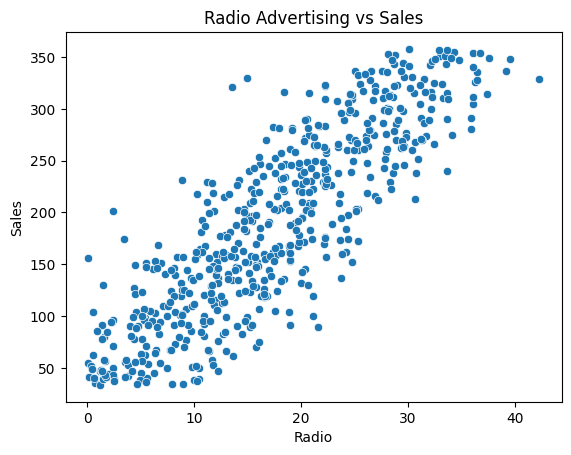

In [26]:
sns.scatterplot(data=df, x='Radio', y='Sales')
plt.title('Radio Advertising vs Sales')
plt.show()

### 4. Split the data into training and testing sets

In [29]:
#training set to train the model, test set to test the model created
# 80/20 or 75/25. Majority size should be for training. More data = more accurate
train = df.sample(frac=0.8, random_state=13) # random state: allows reuse of the SAME randome algorithm

#creates test data by dropping all training data
test = df.drop(train.index)

print(train.shape)
print(test.shape)

train_subset = train[["Radio", "Sales"]].copy()
test_subset = test[["Radio", "Sales"]].copy()

display(train_subset.head())
display(test_subset.head())

(458, 5)
(114, 5)


,Radio,Sales
142,7.244487,141.009684
326,29.098840,288.835408
397,9.103024,124.762506
44,16.123668,253.172404
374,36.126135,311.743669


,Radio,Sales
1,7.756876,67.574904
3,20.108487,195.102176
11,6.233074,45.074834
16,30.702258,267.521990
26,1.237599,46.574020


### 5. Fit the OLS regression Model
Formula Sales is the dependent variable (response) and Radio is the independent (predictor) variable

In [31]:
#Creating an OLS model object using the training data
ols_market = ols(formula='Sales ~ Radio', data=train_subset)

#Estimate the model coefficients using the training data
model = ols_market.fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.741
Model:                            OLS   Adj. R-squared:                  0.740
Method:                 Least Squares   F-statistic:                     1304.
Date:                Tue, 17 Nov 2026   Prob (F-statistic):          7.94e-136
Time:                        14:13:06   Log-Likelihood:                -2397.8
No. Observations:                 458   AIC:                             4800.
Df Residuals:                     456   BIC:                             4808.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     45.8116      4.586      9.990      0.0

### 6. Check Linearity
Regression line should represent the relationship reasonalby well. Looking for roughly a straight line, no curve. (Usefule for evidence but it does not prove linearity assumption along)

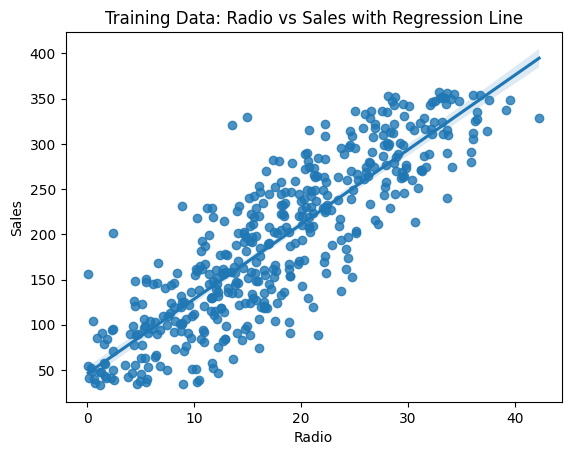

In [32]:
sns.regplot(data=train_subset, x="Radio", y="Sales")
plt.title('Training Data: Radio vs Sales with Regression Line')
plt.show()

### 7. Examine our residuals
Residuals = What we observed - model's predicted value
Residuals help us assess how the model's predictions differ from the training observations. How close is our model?

[]

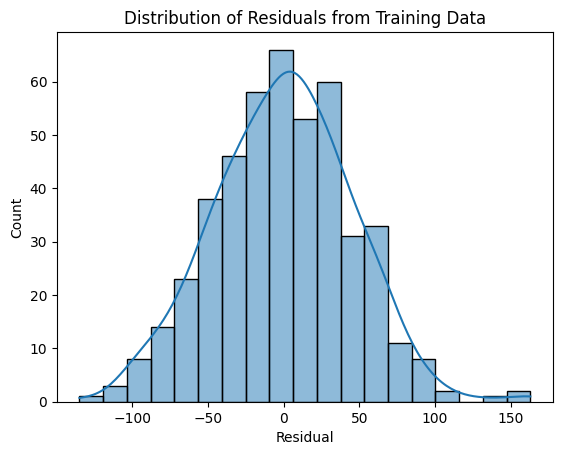

In [33]:
# REsiduals are available from the fitted model
residuals = model.resid

sns.histplot(residuals, kde=True) #KDE kernel density estimate (smoothed out distribution)
plt.xlabel('Residual')
plt.title('Distribution of Residuals from Training Data')
plt.plot()

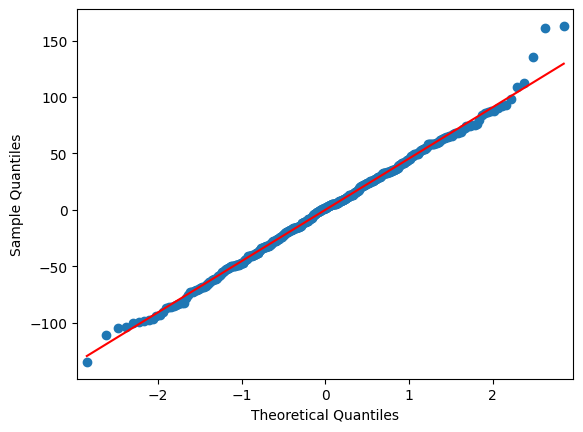

In [34]:
sm.qqplot(residuals, line='s')
plt.show()

### 8. Examine homoscedasticity
A residual-vs-fitted plot to assess whether residuals are centered around zero and have roughly constant speak across all values
- Random cloud or data points (Homoscedasticity) = Good 
- Funnel shapes (heteroskedacity) = Bad
- a curve or other systemic pattern = model is bad or missing a needed variable

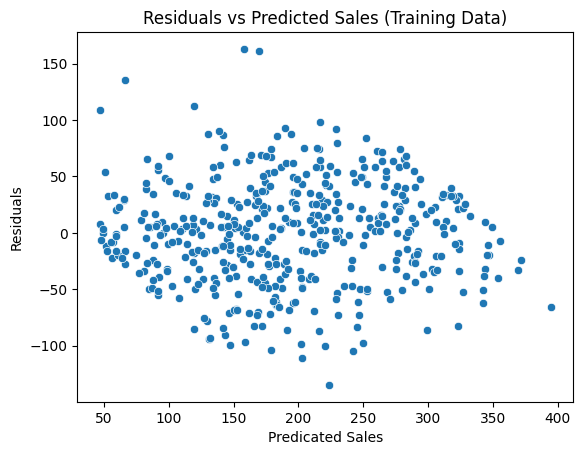

In [36]:
#Giving our model the radio data and asking it to predict sales
pred_train = model.predict(train_subset['Radio'])

sns.scatterplot(x=pred_train, y=residuals)
plt.xlabel('Predicated Sales')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Sales (Training Data)')
plt.show()

### 9. Generate predictions for all data

In [41]:
pred_test = model.predict(test_subset["Radio"])

# Print actual vs predicted and residuals
print('Training Data')
display(pd.DataFrame({
    "Actual Sales": train_subset['Sales'],
    "Predicted Sales": pred_train,
    "Residuals": train_subset['Sales'] - pred_train
}).head())

print('Test Data')
display(pd.DataFrame({
    "Actual Sales": test_subset['Sales'],
    "Predicted Sales": pred_test,
    "Residuals": test_subset['Sales'] - pred_test
}).head())

Training Data


,Actual Sales,Predicted Sales,Residuals
142,141.009684,105.608197,35.401487
326,288.835408,285.995765,2.839643
397,124.762506,120.948712,3.813794
44,253.172404,178.897661,74.274743
374,311.743669,343.999616,-32.255947


Test Data


,Actual Sales,Predicted Sales,Residuals
1,67.574904,109.837493,-42.262590
3,195.102176,211.788673,-16.686497
11,45.074834,97.259909,-52.185075
16,267.521990,299.230503,-31.708513
26,46.574020,56.026860,-9.452840
